In [2]:
import os, sys, json
REPO_URL = "https://github.com/SantiagoPerdomo25/cnn-flores"
if "google.colab" in sys.modules and not os.path.exists("src"):
    !git clone {REPO_URL} repo
    %cd repo
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from PIL import Image
from src import data, model as model_lib, evaluate

tf.keras.utils.set_random_seed(data.SEED)
print("TensorFlow:", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Selección y descripción del dataset

Se usa **TF Flowers** (publicado por el equipo de TensorFlow): ~3.670 fotografías a color de flores en 5 clases: `daisy`, `dandelion`, `roses`, `sunflowers` y `tulips`.

**Por qué este dataset:**
- Es un problema de clasificación multiclase real, con fotos en condiciones variadas (ángulo, luz, fondo).
- Tiene tamaño suficiente para entrenar una CNN desde cero en Colab en pocos minutos.
- Las imágenes tienen tamaños diferentes, lo que obliga a hacer un preprocesamiento real.
- Al ser un dataset moderado, el *Data Augmentation* es realmente necesario para reducir el sobreajuste.

Clases: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Total de imágenes: 3670


,imágenes
daisy,633
dandelion,898
roses,641
sunflowers,699
tulips,799


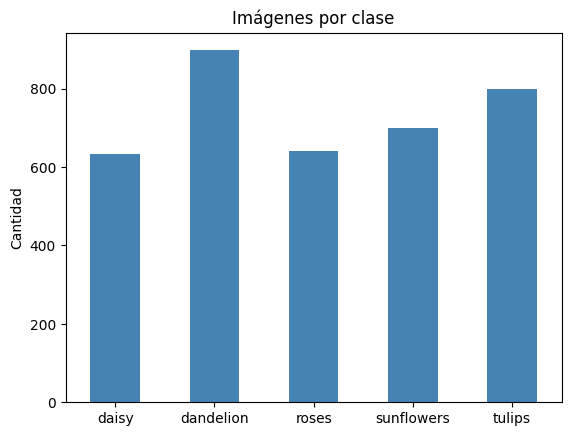

In [3]:
data_dir = data.download_dataset("data")
paths, labels, class_names = data.list_images(data_dir)
print("Clases:", class_names)
print("Total de imágenes:", len(paths))

counts = pd.Series(labels).map(dict(enumerate(class_names))).value_counts().sort_index()
display(counts.to_frame("imágenes"))
counts.plot(kind="bar", color="steelblue", title="Imágenes por clase", rot=0)
plt.ylabel("Cantidad"); plt.show()

## 2. Exploración y visualización de las imágenes

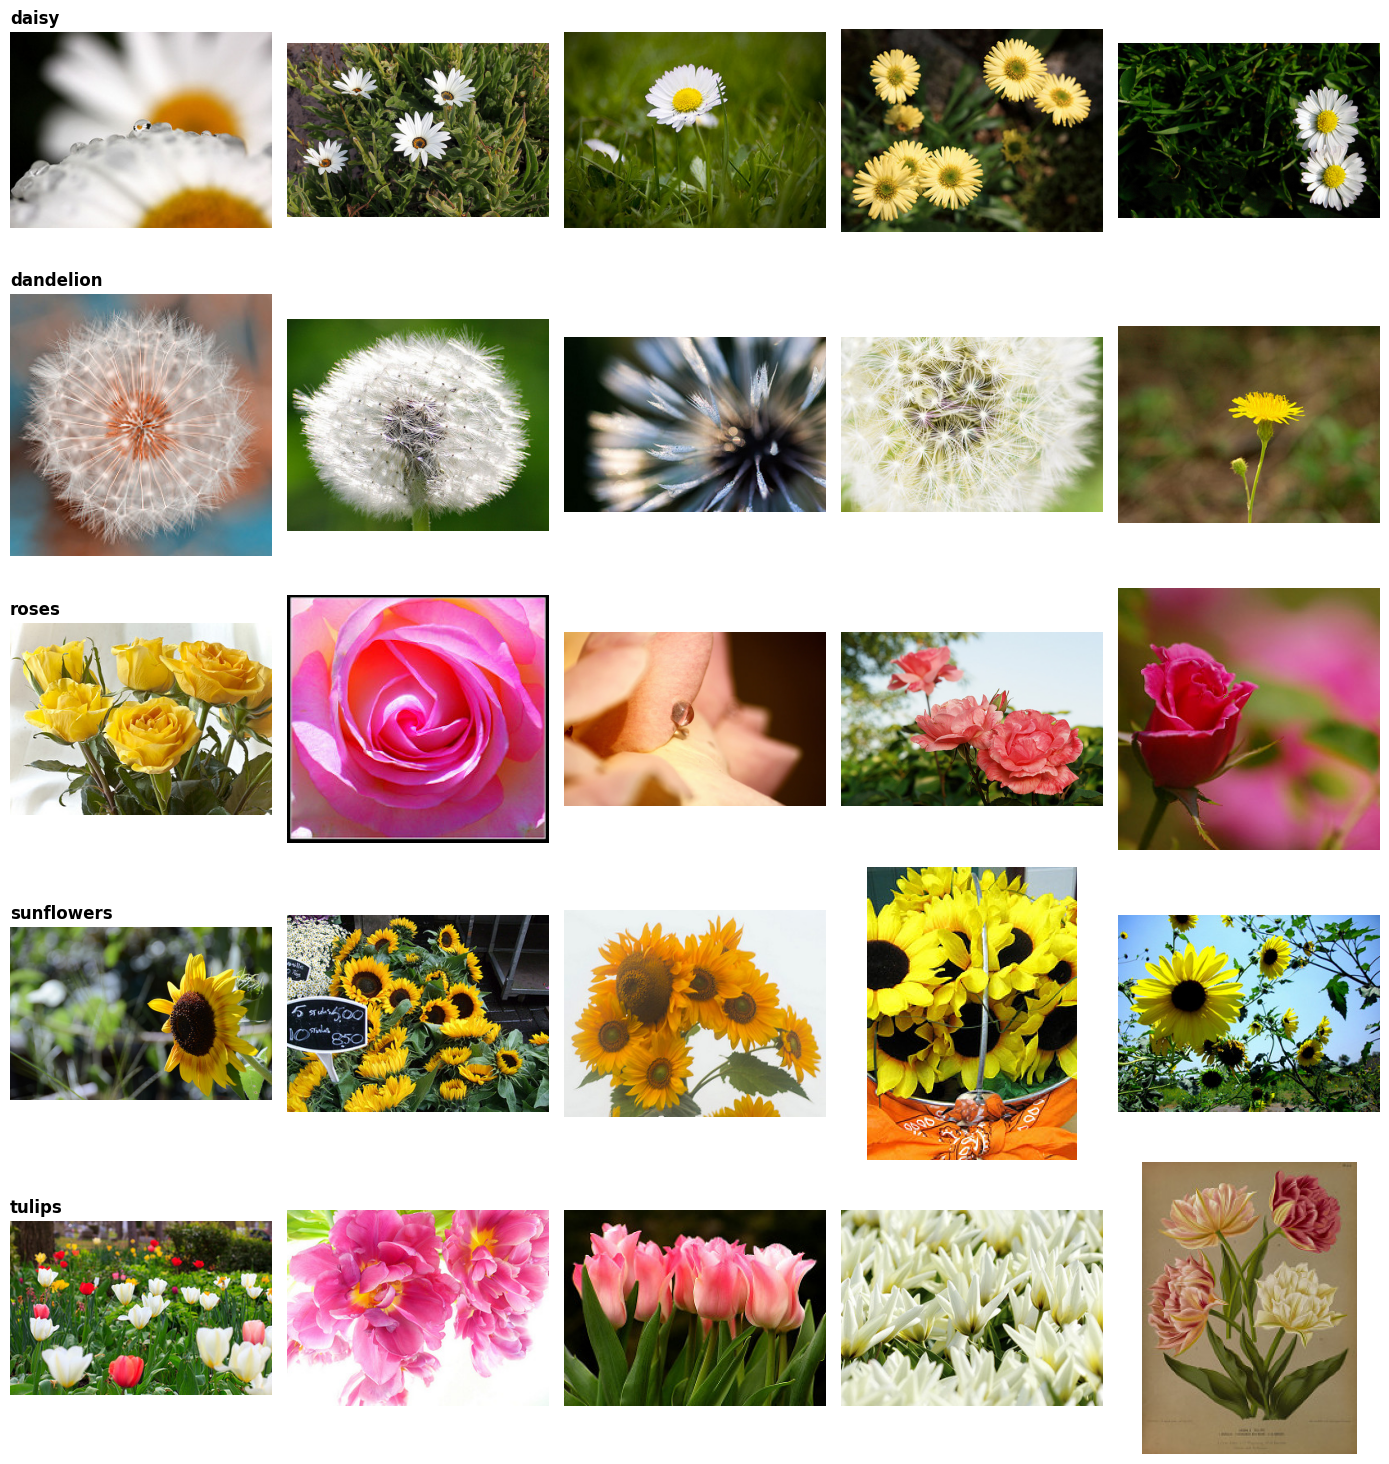

In [4]:
fig, axes = plt.subplots(len(class_names), 5, figsize=(14, 3 * len(class_names)))
rng = np.random.default_rng(1)
for r, c in enumerate(class_names):
    idx = rng.choice(np.where(labels == r)[0], 5, replace=False)
    for k, i in enumerate(idx):
        axes[r, k].imshow(Image.open(paths[i])); axes[r, k].axis("off")
    axes[r, 0].set_title(c, loc="left", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

Ancho:  min=145  media=367  max=500
Alto:   min=199  media=272  max=441


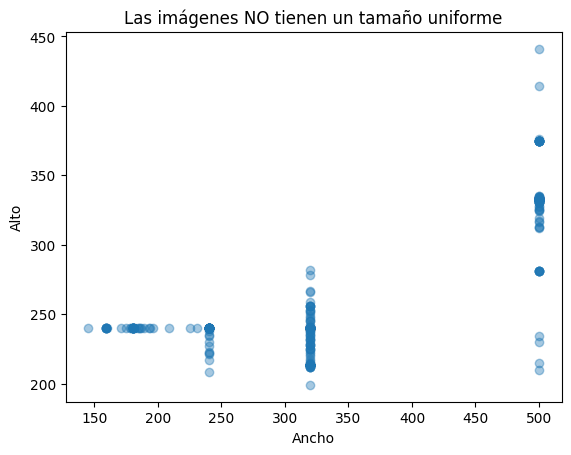

In [5]:
# Tamaños originales (muestra de 400 imágenes) para justificar el redimensionado
sample = rng.choice(len(paths), 400, replace=False)
sizes = np.array([Image.open(paths[i]).size for i in sample])
print(f"Ancho:  min={sizes[:,0].min()}  media={sizes[:,0].mean():.0f}  max={sizes[:,0].max()}")
print(f"Alto:   min={sizes[:,1].min()}  media={sizes[:,1].mean():.0f}  max={sizes[:,1].max()}")
plt.scatter(sizes[:,0], sizes[:,1], alpha=.4); plt.xlabel("Ancho"); plt.ylabel("Alto")
plt.title("Las imágenes NO tienen un tamaño uniforme"); plt.show()

## 3. Preprocesamiento, normalización y división de datos

- **Redimensionado** a 180×180 píxeles (tamaño único para la red).
- **Normalización** de los píxeles de [0, 255] a [0, 1] mediante una capa `Rescaling` *dentro* del modelo. Así la app Streamlit solo debe pasar la imagen redimensionada y se evita cualquier desajuste entre entrenamiento e inferencia.
- **División estratificada** (mantiene la proporción de clases): **70 % entrenamiento / 15 % validación / 15 % prueba**. El conjunto de prueba no se toca hasta la evaluación final.

In [6]:
IMG_SIZE = (180, 180)
BATCH_SIZE = 32
ds, splits, class_names = data.build_datasets(data_dir, IMG_SIZE, BATCH_SIZE)

rows = []
for name, (p, y) in splits.items():
    row = {"conjunto": name, "total": len(p)}
    row.update({c: int((y == i).sum()) for i, c in enumerate(class_names)})
    rows.append(row)
display(pd.DataFrame(rows).set_index("conjunto"))

x, y = next(iter(ds["train"]))
print("Batch:", x.shape, x.dtype, "| rango píxeles:", float(x.numpy().min()), "-", float(x.numpy().max()))

,total,daisy,dandelion,roses,sunflowers,tulips
conjunto,,,,,,
train,2569,443,629,449,489,559
val,550,95,134,96,105,120
test,551,95,135,96,105,120


Batch: (32, 180, 180, 3) <dtype: 'float32'> | rango píxeles: 0.0 - 255.0


## 4. Data Augmentation

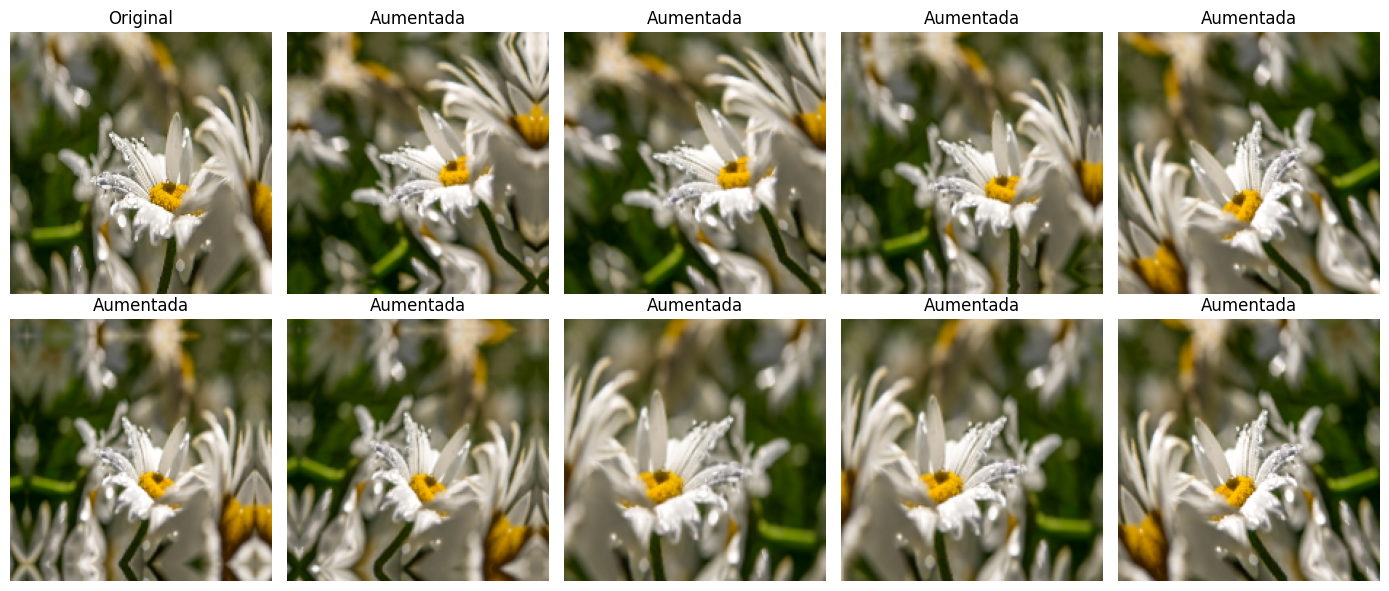

In [7]:
aug = model_lib.build_augmentation()
img = x[:1]
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
axes[0, 0].imshow(img[0].numpy().astype("uint8")); axes[0, 0].set_title("Original")
for ax in axes.ravel()[1:]:
    ax.imshow(aug(img, training=True)[0].numpy().clip(0, 255).astype("uint8"))
    ax.set_title("Aumentada")
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Construcción de la CNN

Arquitectura: *Data Augmentation → Rescaling → 4 bloques [Conv-BN-ReLU ×2 + MaxPool] (32→256 filtros) → GlobalAveragePooling → Dense(128) → Dropout(0.5) → Softmax(5)*.
`BatchNormalization`, `Dropout` y el aumento de datos se utilizan para controlar el sobreajuste.

In [8]:
model = model_lib.build_cnn(IMG_SIZE + (3,), len(class_names))
model.summary()

Model: "cnn_flores"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 180, 180, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 180, 180, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 180, 180, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 180, 180, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 180, 180, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 90, 90, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 90, 90, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 90, 90, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 90, 90, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 90, 90, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 90, 90, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 45, 45, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 45, 45, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 45, 45, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 45, 45, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 45, 45, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 1,208,677 (4.61 MB)

 Trainable params: 1,206,757 (4.60 MB)

 Non-trainable params: 1,920 (7.50 KB)

## 6. Entrenamiento

In [9]:
os.makedirs("models", exist_ok=True); os.makedirs("reports", exist_ok=True)
callbacks = [
    tf.keras.callbacks.ModelCheckpoint("models/cnn_flores.keras", monitor="val_accuracy", save_best_only=True),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
]
history = model.fit(ds["train"], validation_data=ds["val"], epochs=40, callbacks=callbacks)

Epoch 1/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 29s 225ms/step - accuracy: 0.5021 - loss: 1.2810 - val_accuracy: 0.2436 - val_loss: 1.9638 - learning_rate: 0.0010
Epoch 2/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 16s 199ms/step - accuracy: 0.5745 - loss: 1.0862 - val_accuracy: 0.2436 - val_loss: 2.1121 - learning_rate: 0.0010
Epoch 3/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 203ms/step - accuracy: 0.5983 - loss: 0.9854 - val_accuracy: 0.2800 - val_loss: 2.6516 - learning_rate: 0.0010
Epoch 4/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 207ms/step - accuracy: 0.6384 - loss: 0.9387 - val_accuracy: 0.3782 - val_loss: 1.8229 - learning_rate: 0.0010
Epoch 5/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 209ms/step - accuracy: 0.6411 - loss: 0.9319 - val_accuracy: 0.4855 - val_loss: 1.2876 - learning_rate: 0.0010
Epoch 6/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 210ms/step - accuracy: 0.6536 - loss: 0.8967 - val_accuracy: 0.5945 - val_loss: 1.1273 - learning_rate: 0.0010
Epoch 7/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 17s 215ms/step - accuracy: 0.6610 - loss: 0.

## 7. Gráficas del entrenamiento

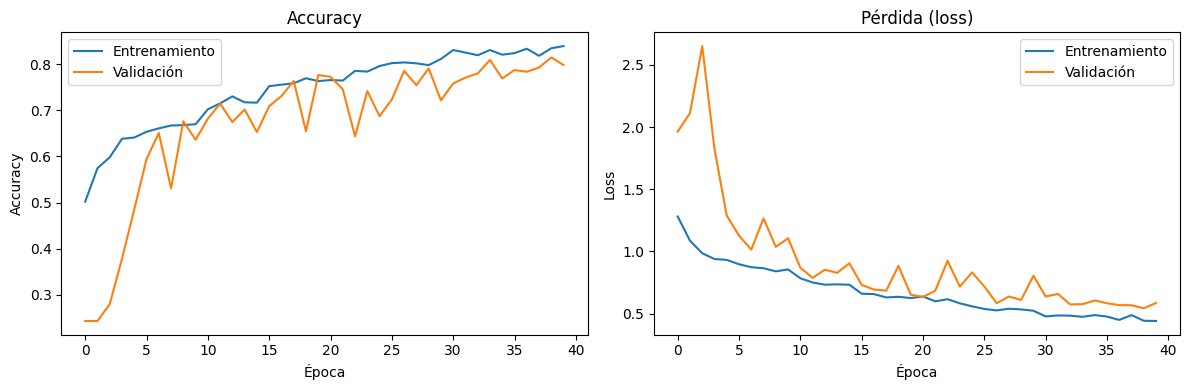

In [10]:
evaluate.plot_history(history, "reports/training_curves.png"); plt.show()

## 8. Evaluación en el conjunto de prueba

Se usan **accuracy**, **precision, recall y F1 por clase** (más informativas que el accuracy solo) y la **matriz de confusión**.

In [11]:
test_loss, test_acc = model.evaluate(ds["test"], verbose=0)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}\n")
y_true, y_pred, probs = evaluate.get_predictions(model, ds["test"])
print(evaluate.text_report(y_true, y_pred, class_names))

Test loss: 0.5509 | Test accuracy: 0.8058

              precision    recall  f1-score   support

       daisy      0.780     0.821     0.800        95
   dandelion      0.880     0.815     0.846       135
       roses      0.724     0.740     0.732        96
  sunflowers      0.848     0.905     0.876       105
      tulips      0.776     0.750     0.763       120

    accuracy                          0.806       551
   macro avg      0.802     0.806     0.803       551
weighted avg      0.807     0.806     0.806       551



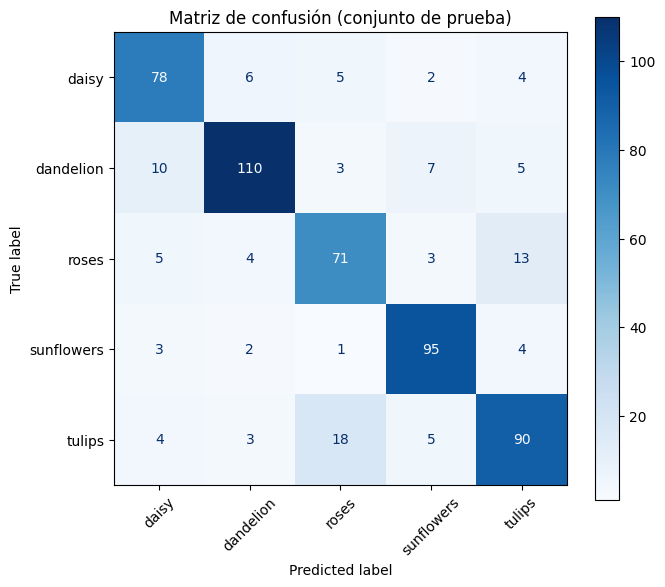

In [12]:
evaluate.plot_confusion_matrix(y_true, y_pred, class_names, "reports/confusion_matrix.png"); plt.show()

## 9. Predicciones con imágenes (12 imágenes del conjunto de prueba)

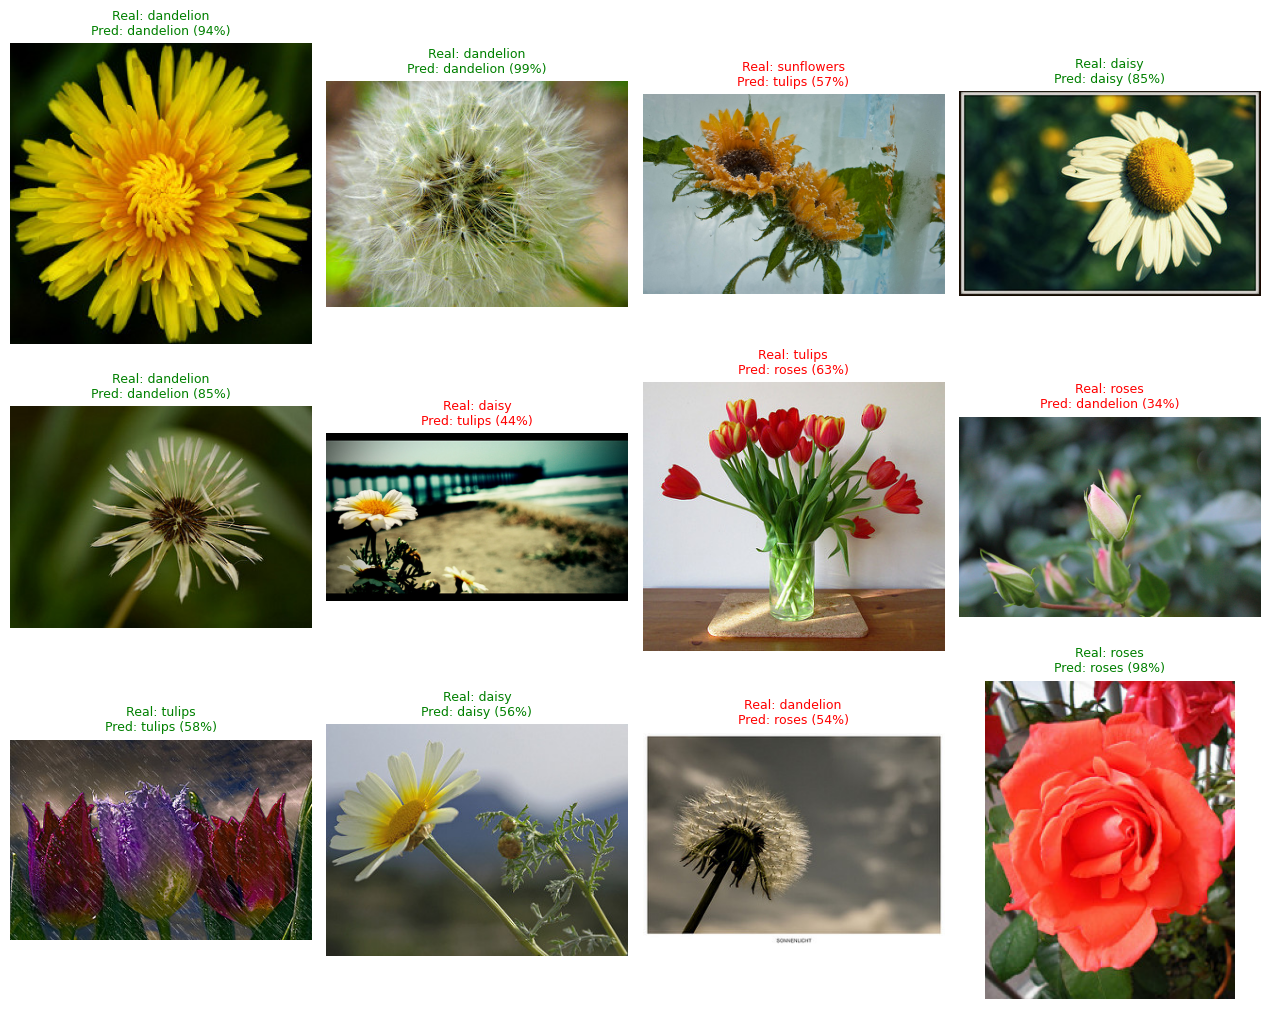

In [13]:
p_te, y_te = splits["test"]
evaluate.show_predictions(model, p_te, y_te, class_names, n=12, img_size=IMG_SIZE,
                          path="reports/predictions.png"); plt.show()

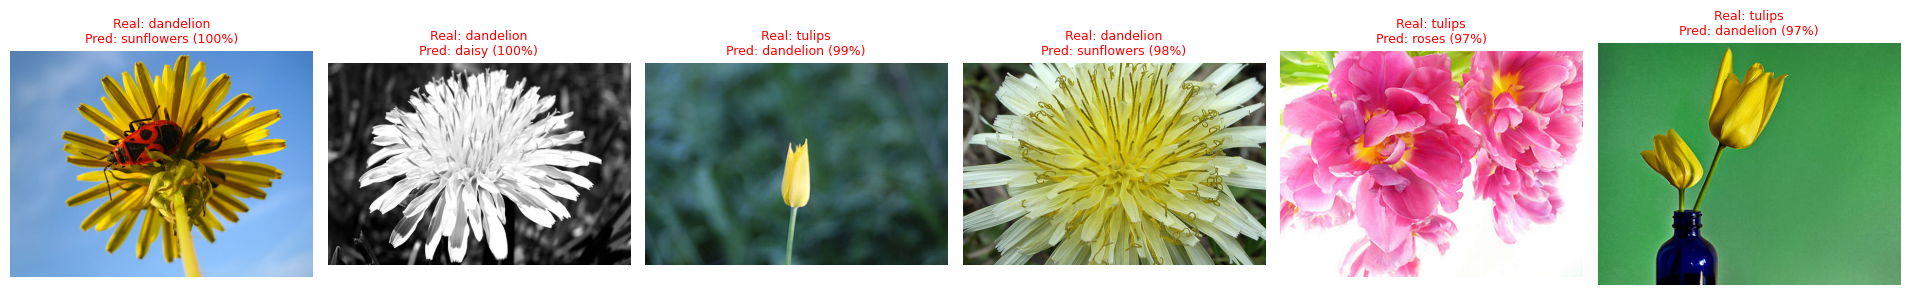

In [14]:
wrong = np.where(y_true != y_pred)[0]
worst = wrong[np.argsort(-probs[wrong].max(axis=1))][:6]
fig, axes = plt.subplots(1, len(worst), figsize=(3.2 * len(worst), 3.6))
for ax, i in zip(np.atleast_1d(axes), worst):
    ax.imshow(Image.open(p_te[i])); ax.axis("off")
    ax.set_title(f"Real: {class_names[y_true[i]]}\nPred: {class_names[y_pred[i]]} ({probs[i].max():.0%})",
                 color="red", fontsize=9)
plt.tight_layout(); plt.show()

## 10. Guardado del modelo

In [15]:
model.save("models/cnn_flores.keras")
with open("models/class_names.json", "w", encoding="utf-8") as f:
    json.dump(class_names, f)
with open("reports/history.json", "w") as f:
    json.dump(history.history, f)
with open("reports/classification_report.txt", "w", encoding="utf-8") as f:
    f.write(evaluate.text_report(y_true, y_pred, class_names))
print("Modelo guardado en models/cnn_flores.keras")

from src.predict import load_artifacts, predict_image
m2, names = load_artifacts()
print(predict_image(m2, Image.open(p_te[0]), names))

Modelo guardado en models/cnn_flores.keras
{'class': 'roses', 'confidence': 0.928547203540802, 'probabilities': {'daisy': 0.005671322345733643, 'dandelion': 1.7533417121740058e-05, 'roses': 0.928547203540802, 'sunflowers': 4.479954804992303e-05, 'tulips': 0.06571907550096512}}


In [16]:
if "google.colab" in sys.modules:
    !zip -r artefactos.zip models reports
    from google.colab import files
    files.download("artefactos.zip")

  adding: models/ (stored 0%)
  adding: models/.gitkeep (stored 0%)
  adding: models/class_names.json (deflated 13%)
  adding: models/cnn_flores.keras (deflated 9%)
  adding: reports/ (stored 0%)
  adding: reports/predictions.png (deflated 0%)
  adding: reports/.gitkeep (stored 0%)
  adding: reports/confusion_matrix.png (deflated 14%)
  adding: reports/history.json (deflated 62%)
  adding: reports/classification_report.txt (deflated 61%)
  adding: reports/training_curves.png (deflated 7%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>